In [3]:
#Experiential Learning Problem: Student Exam Score Analysis

In [4]:
import numpy as np
from scipy.stats import t, ttest_1samp
import matplotlib.pyplot as plt


In [5]:
# Step 1: Simulate sample exam scores from 30 students
np.random.seed(42)
scores = np.random.normal(loc=395, scale=5, size=30)  # mean > 68 (historical avg)


In [6]:
# Step 2: One-tailed t-test (H0: μ <= 68, H1: μ > 68)
sample_mean = np.mean(scores)
sample_std = np.std(scores, ddof=1)
n = len(scores)

t_stat = (sample_mean - 68) / (sample_std / np.sqrt(n))
p_value = 1 - t.cdf(t_stat, df=n-1)  # one-tailed



In [7]:
# Output test results
print("Sample Mean:", round(sample_mean, 2))
print("Sample Std Dev:", round(sample_std, 2))
print("T-Statistic:", round(t_stat, 3))
print("P-value (one-tailed):", round(p_value, ))

alpha = 0.05
if p_value < alpha:
    print("Reject H₀: The teaching intervention significantly improved scores.")
else:
    print(" Fail to reject H₀: Not enough evidence of improvement.")


Sample Mean: 394.06
Sample Std Dev: 4.5
T-Statistic: 396.864
P-value (one-tailed): 0.0
Reject H₀: The teaching intervention significantly improved scores.


In [8]:
# Step 3: 95% Confidence Interval for the sample mean
t_critical = t.ppf(1 - alpha/2, df=n-1)
margin_error = t_critical * sample_std / np.sqrt(n)
ci_lower = sample_mean - margin_error
ci_upper = sample_mean + margin_error

print(f"95% Confidence Interval: ({ci_lower:.2f}, {ci_upper:.2f})")


95% Confidence Interval: (392.38, 395.74)


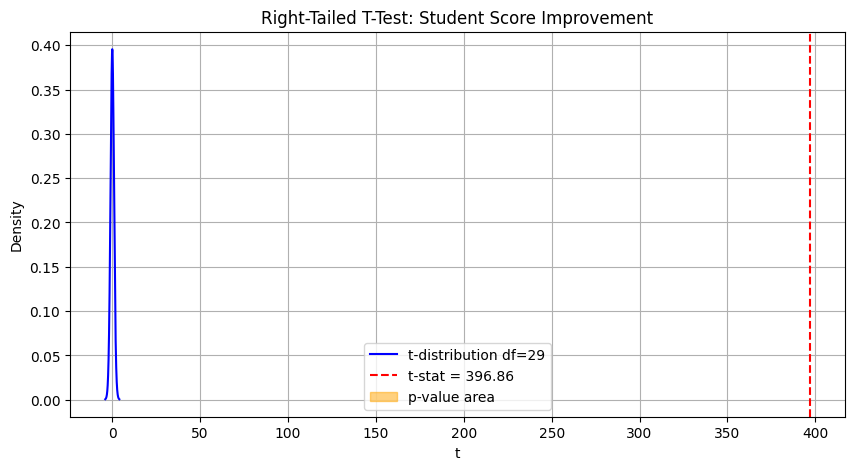

In [9]:
 #Visualization of the t-distribution and P-value
# Step 4: Plotting the t-distribution with p-value area
x = np.linspace(-4, 4, 500)
t_dist = t.pdf(x, df=n-1)

plt.figure(figsize=(10, 5))
plt.plot(x, t_dist, label='t-distribution df=29', color='blue')
plt.axvline(t_stat, color='red', linestyle='--', label=f't-stat = {t_stat:.2f}')
plt.fill_between(x, 0, t_dist, where=(x >= t_stat), color='orange', alpha=0.5, label='p-value area')
plt.title("Right-Tailed T-Test: Student Score Improvement")
plt.xlabel("t")
plt.ylabel("Density")
plt.legend()
plt.grid(True)
plt.show()
